In [1]:
import numpy as np
import pandas as pd

In [246]:
anomalies = pd.read_csv("labeled_anomalies.csv")
anomalies

,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307
...,...,...,...,...,...
77,P-11,MSL,"[[1778, 1898], [1238, 1344]]","[point, point]",3535
78,D-15,MSL,"[[1500, 2140]]",[point],2158
79,D-16,MSL,"[[600, 1250]]",[contextual],2191
80,M-7,MSL,"[[940, 1040]]",[point],2156


In [248]:
#We make two anomalies dataset, one for SMAP and one for MSL
anomalies_SMAP = anomalies[anomalies.spacecraft=="SMAP"]
anomalies_MSL = anomalies[anomalies.spacecraft=="MSL"]

Now let us try to understand telemetary data. The channel ID is a unique ID that is exactly on one spacecraft. The first column represents the readings of the Telmetary channel which is normalized to between -1 and 1. The other columns record any other change made in the spacecraft before recording the telemetary reading. This is important, for instance, you would want to know that a heater was turned on before recording the temperature.

It is important to figure out which channel_id belongs to which spacecraft before analyzing data. We obtain this information from the anomalies_SMAP or anomalies_MSL variables which contains the list of channel_id for SMAP and MSL respectively stored under the column "chan_id"

There are two directories data/test and data/train.  Train only contains a subset of rows and Test contains all the rows. So we perform EDA on the test data which is all the information. 

In [249]:
#Just to get a feel for that data, let us look at P1-channel which belongs to SMAP. This will have
# (1 + 24) features
P1=np.load("data/data/test/P-1.npy")
P1=pd.DataFrame(P1)

In [250]:
#Let us drop the one hot encoded feature columns that have not changed at all.
drop = [col for col in P1.columns.tolist() if P1[col].unique().size==1]
drop


[4, 10, 15, 16, 20, 23, 24]

In [251]:
P1 = P1[[i for i in P1.columns.tolist() if i not in drop]]

In [252]:
#There are still some duplicated columns. We can use the following to know what is duplicated.
repeated = P1.T.duplicated()
repeated

0     False
1     False
2     False
3     False
5     False
6     False
7     False
8     False
9     False
11    False
12    False
13    False
14     True
17    False
18     True
19    False
21    False
22    False
dtype: bool

In [253]:
#Let us drop the repeated columns i.e 14 and 18
P1 = P1.drop(columns=[14,18])


In [254]:
#One small problem to note is that anomaly_sequences column is actually a string
anomalies_SMAP[anomalies_SMAP.chan_id=="P-1"]["anomaly_sequences"][0]

'[[2149, 2349], [4536, 4844], [3539, 3779]]'

In [255]:
#We use ast to convert a string to a list
import ast
anomaly_sequence = ast.literal_eval(anomalies_SMAP[anomalies_SMAP.chan_id=="P-1"]["anomaly_sequences"][0])
#Now we have a list of lists
anomaly_sequence

[[2149, 2349], [4536, 4844], [3539, 3779]]

In [256]:
#here is a snapshot of our data so far
P1

,0,1,2,3,5,6,7,8,9,11,12,13,17,19,21,22
0,-0.695162,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.685704,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.725719,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.761368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.745362,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8500,0.293561,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8501,0.341579,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0
8502,-0.316115,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8503,-0.297199,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [257]:
#We will store all the one hot encoded columns in a list
OHF=P1.columns.tolist()[1:]
print(OHF)
print(f"There are {len(OHF)} one hot encoded features")

[1, 2, 3, 5, 6, 7, 8, 9, 11, 12, 13, 17, 19, 21, 22]
There are 15 one hot encoded features


# Models
Now that we have see the graphs, let us just fit a model naively and try to predict. For our training data we are going to use the values upto 2000 where there are no anomalies. After that we will try to fit the model on all of our data. We will use a regressor model to predict what the correct reading should be. The anomalies will occur at those places where there is a big error between the predicted values and actual values. Note that we could also think about using a classifier model; this could be more useful for point anamoly. Perhaps a way to use classifier model for contextual anomaly is to consider sub-intervals as features with a sliding scale.

On the other hand, the whole problem could be treated as a categorical problem where we predict if something is an anomaly or not. There is a very big class imbalance so logistic regression is probably a bad idea. There are classification models that can handle such large class imbalances like XGBoost, Random Forests etc.

However, I think there is a problem with treating it as a categorical problem. You are making an assumption that your target is a function of your features, but an anamoly happens precisely in the case that the target is not a function of features.

We will fit LinearRegression to perform a forecasting. Then we will find anomalies when the prediction and observed value have very large error.

In [266]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

In [269]:
P1["time"]= P1.index    #We need a column that records the time
df = P1.iloc[:2001]     #We will only work with the first 2000 values
X=df.iloc[:,1:]         #features
y=df[[0]]               #target
X.columns = X.columns.astype(str) #Converts all column names to string type. If there is a mix of str and int, fitting gives an error
X

,1,2,3,5,6,7,8,9,11,12,13,17,19,21,22,time
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1996,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1996
1997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1997
1998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1998
1999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1999


In [270]:
y

,0
0,-0.695162
1,-0.685704
2,-0.725719
3,-0.761368
4,-0.745362
...,...
1996,-0.762095
1997,-0.751182
1998,-0.744634
1999,-0.791924


In [274]:
#OHF contains the one-hot-enocded feature colmuns, however this  is int. We need to convert 
#it to a string
print(OHF)
OHF = [str(x) for x in OHF]
print(OHF)

[1, 2, 3, 5, 6, 7, 8, 9, 11, 12, 13, 17, 19, 21, 22]
['1', '2', '3', '5', '6', '7', '8', '9', '11', '12', '13', '17', '19', '21', '22']


In [275]:
#Apply column transformations to get the sine/cosine functions of time. Recall that the period is 50.
#Apply PCA to drop some of the one hot encoded features that are sparse
trig_pca = ColumnTransformer(transformers = [
                               ("sine", FunctionTransformer(lambda x : np.sin(2*np.pi*x/50)) , ["time"]),
                               ("cos" , FunctionTransformer(lambda y : np.cos(2*np.pi*y/50)), ["time"]),
                               ("pca", PCA(n_components=5), OHF)
                               ],
                               remainder="passthrough")

In [276]:
#Let us build our linear model
linear_model = Pipeline(steps=[
                        ("preprocess" , trig_pca),
                        ("linear_model" , LinearRegression())
                            ])
linear_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('linear_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('sine', ...), ('cos', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float,

Now that we have our model, we have to figure out how to split out data into train/test. We will use TimeSeriesSplit form sklearn.model_selection. There are other ways to split data. See here: https://medium.com/@mouadenna/time-series-splitting-techniques-ensuring-accurate-model-validation-5a3146db3088

In [279]:
from sklearn.model_selection import TimeSeriesSplit
time_split  = TimeSeriesSplit(n_splits=5)

#Create a dataframe to record the root mean squared error and mean absolute error
row_names = [f"Fold {i+1}" for i in range(5)]
col_names = ["RMSE","MAE"]
error = pd.DataFrame(np.nan ,index = row_names, columns = col_names)

i=0
for train_index, test_index in time_split.split(df):
    #training and test data
    X_train=X.iloc[train_index]
    y_train = y.iloc[train_index]
    X_test = X.iloc[test_index]
    y_test = y.iloc[test_index]

    #fit and predict
    linear_model.fit(X_train , y_train)
    y_pred = linear_model.predict(X_test)
    error.iloc[i,0] = root_mean_squared_error(y_test,y_pred)
    error.iloc[i,1] = mean_absolute_error(y_test,y_pred)
    i+=1
    
print(error)    

            RMSE       MAE
Fold 1  0.308953  0.244654
Fold 2  0.327893  0.253717
Fold 3  0.307501  0.251103
Fold 4  0.300821  0.237763
Fold 5  0.304839  0.243001


Seems like our model is mostly consistent. Now we will run our model on the whole dataset and see when the errors are super large. We will do  this by plotting rmse and mae for 50 period intervals.

In [336]:
row_names= [f"{i}" for i in range(100)]
col_names=["RMSE","MAE"]
interval_error = pd.DataFrame(np.nan ,index = row_names, columns = col_names)

In [329]:
P1.columns = P1.columns.astype(str)

In [337]:
for i  in range(100):
    interval_error.iloc[i,0] = root_mean_squared_error(P1.iloc[i*50:(i+1)*50,0],linear_model.predict(P1.iloc[i*50:(i+1)*50,1:]))
    interval_error.iloc[i,1] = mean_absolute_error(P1.iloc[i*50:(i+1)*50,0],linear_model.predict(P1.iloc[i*50:(i+1)*50,1:]))

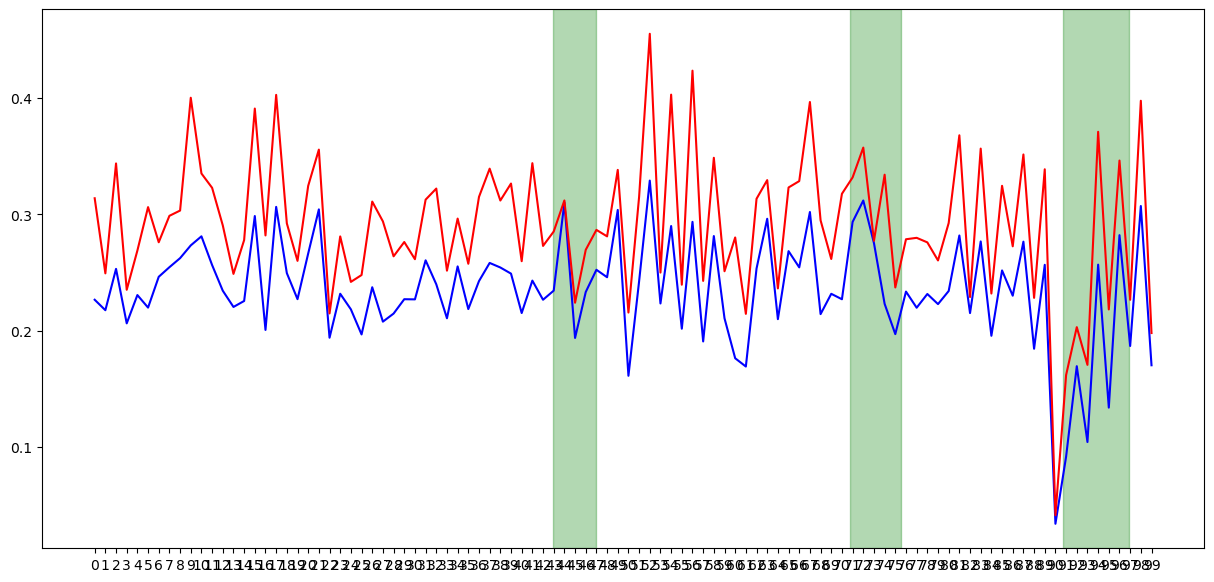

In [339]:
plt.figure(figsize=(15,7))
plt.plot(interval_error["MAE"], color= "blue")
plt.plot(interval_error["RMSE"], color= "red")
for anomaly in anomaly_sequence:
    plt.axvspan(anomaly[0]/50,anomaly[1]/50, color = "green", alpha = 0.3)